<sub>**The Annotated ML Handbook** · Part IV: Visualization</sub>

# Chapter 14: Matplotlib and Seaborn: from first plot to publication figure

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-4-visualization/14-viz-matplotlib.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 14.1 The anatomy of a figure · *Beginner*

**The object-oriented interface (recommended)**

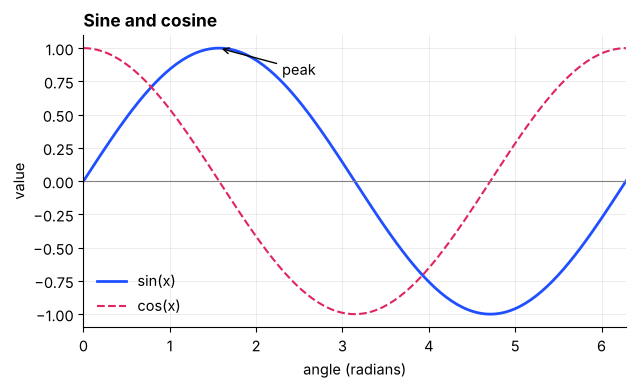

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

x = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(x, np.sin(x), label="sin(x)", lw=2)
ax.plot(x, np.cos(x), label="cos(x)", ls="--")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Sine and cosine")
ax.set_xlabel("angle (radians)")
ax.set_ylabel("value")
ax.set_xlim(0, 2 * np.pi)
ax.legend(loc="lower left")
ax.annotate("peak", xy=(np.pi / 2, 1), xytext=(2.3, 0.8),
            arrowprops=dict(arrowstyle="->"))
plt.show()

## 14.2 The essential chart types · *Beginner*

**Six workhorse plots in a grid**

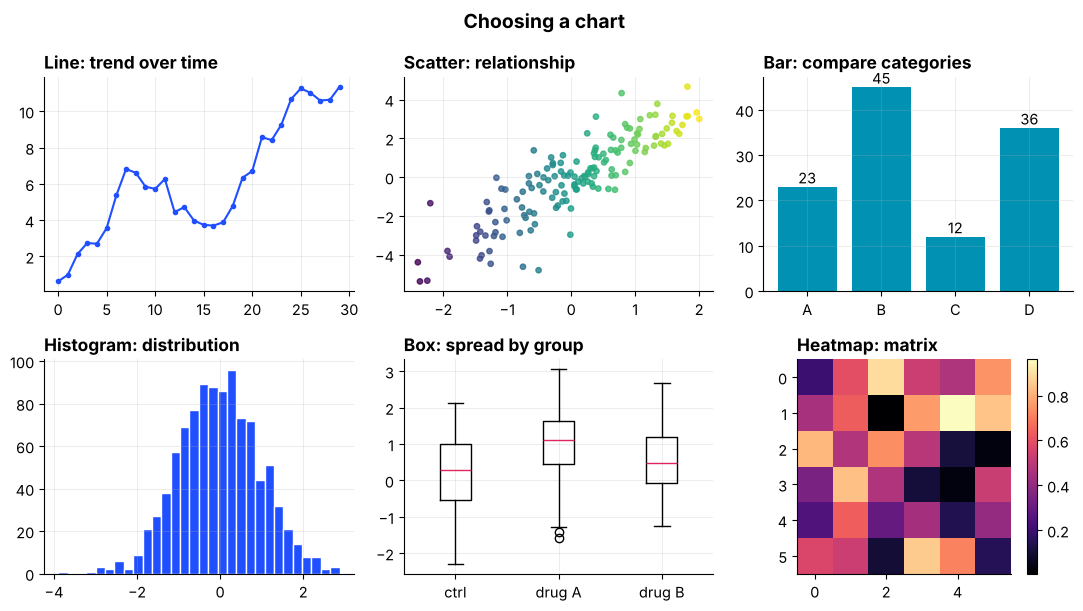

In [3]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))

t = np.arange(30)
axes[0, 0].plot(t, np.cumsum(rng.normal(0.5, 1, 30)), marker="o", ms=3)
axes[0, 0].set_title("Line: trend over time")

a = rng.normal(size=150)
axes[0, 1].scatter(a, 2 * a + rng.normal(size=150), c=a, cmap="viridis", s=15, alpha=0.8)
axes[0, 1].set_title("Scatter: relationship")

cats, vals = ["A", "B", "C", "D"], [23, 45, 12, 36]
bars = axes[0, 2].bar(cats, vals, color="#0091b3")
axes[0, 2].bar_label(bars)
axes[0, 2].set_title("Bar: compare categories")

axes[1, 0].hist(rng.normal(0, 1, 1000), bins=30, edgecolor="white")
axes[1, 0].set_title("Histogram: distribution")

groups = [rng.normal(m, 1, 80) for m in (0, 1, 0.5)]
axes[1, 1].boxplot(groups, tick_labels=["ctrl", "drug A", "drug B"])
axes[1, 1].set_title("Box: spread by group")

im = axes[1, 2].imshow(rng.random((6, 6)), cmap="magma")
fig.colorbar(im, ax=axes[1, 2])
axes[1, 2].set_title("Heatmap: matrix")
axes[1, 2].grid(False)

fig.suptitle("Choosing a chart", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

### 14.2.1 Which chart for which question?

## 14.3 Subplots, shared axes and layouts · *Intermediate*

**Shared axes and uneven layouts**

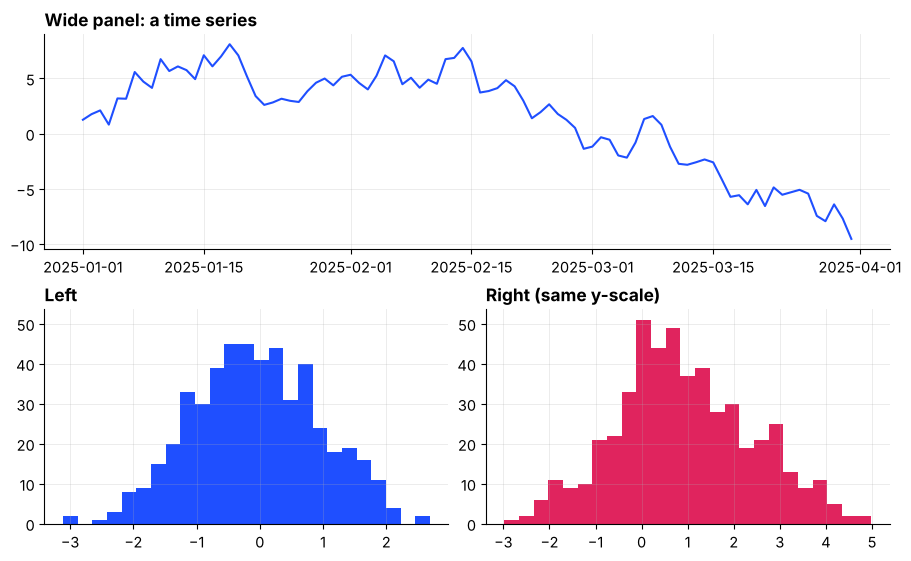

In [4]:
fig, axd = plt.subplot_mosaic([["top", "top"], ["left", "right"]],
                              figsize=(9, 5.5), layout="constrained")
days = pd.date_range("2025-01-01", periods=90)
axd["top"].plot(days, np.cumsum(rng.normal(size=90)))
axd["top"].set_title("Wide panel: a time series")
axd["left"].hist(rng.normal(size=500), bins=25)
axd["left"].set_title("Left")
axd["right"].hist(rng.normal(1, 1.5, 500), bins=25, color="#e0245e")
axd["right"].sharey(axd["left"])
axd["right"].set_title("Right (same y-scale)")
plt.show()

## 14.4 Seaborn: statistical plots in one line · *Beginner*

**Distribution and relationship by group**

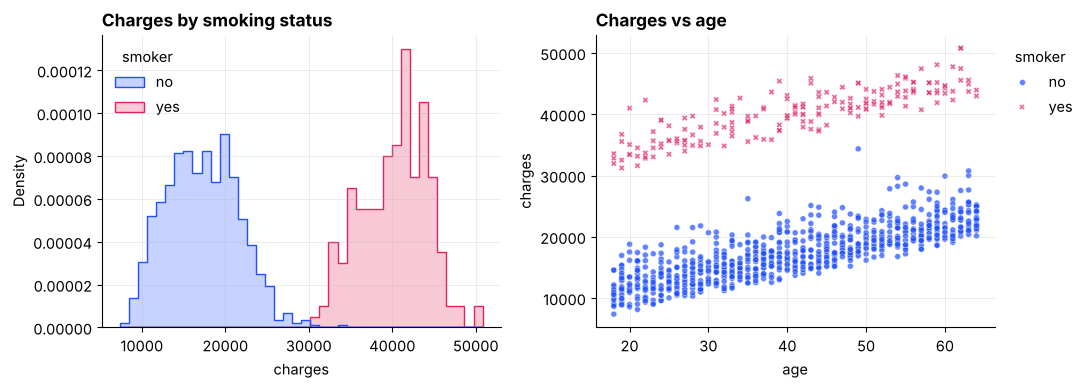

In [5]:
import seaborn as sns

ins = pd.read_csv("insurance.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=ins, x="charges", hue="smoker", bins=40,
             element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Charges by smoking status")
sns.scatterplot(data=ins, x="age", y="charges", hue="smoker",
                style="smoker", s=18, alpha=0.7, ax=axes[1])
axes[1].set_title("Charges vs age")
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

**Comparing groups**

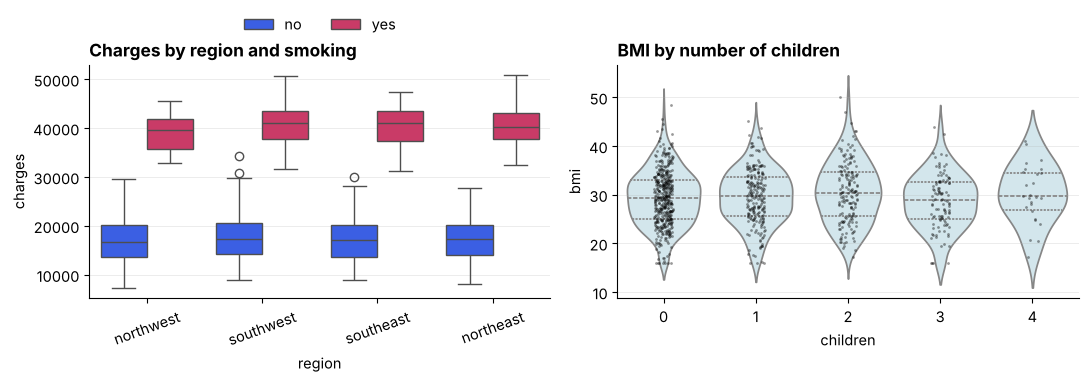

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=ins, x="region", y="charges", hue="smoker", ax=axes[0])
axes[0].set_title("Charges by region and smoking")
axes[0].tick_params(axis="x", rotation=20)
sns.move_legend(axes[0], "lower center", bbox_to_anchor=(0.5, 1.08), ncol=2, title=None)
sns.violinplot(data=ins, x="children", y="bmi", inner="quart", color="#cfe8f0", ax=axes[1])
sns.stripplot(data=ins, x="children", y="bmi", size=2, alpha=0.4, color="k", ax=axes[1])
axes[1].set_title("BMI by number of children")
plt.tight_layout()
plt.show()

**Correlation heatmap**

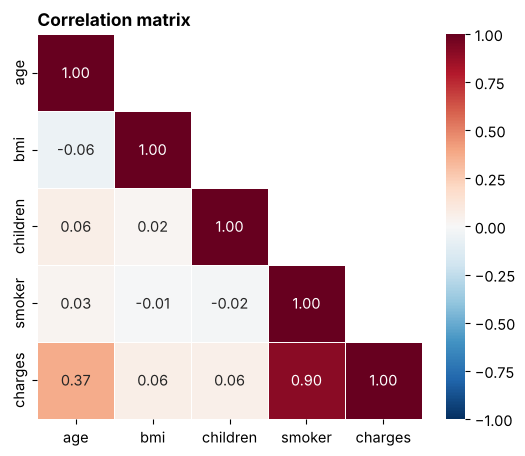

In [7]:
num = ins.assign(smoker=ins["smoker"].eq("yes").astype(int)).select_dtypes("number")
corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation matrix")
ax.grid(False)
plt.show()

**Pair plot: every pair of variables at once**

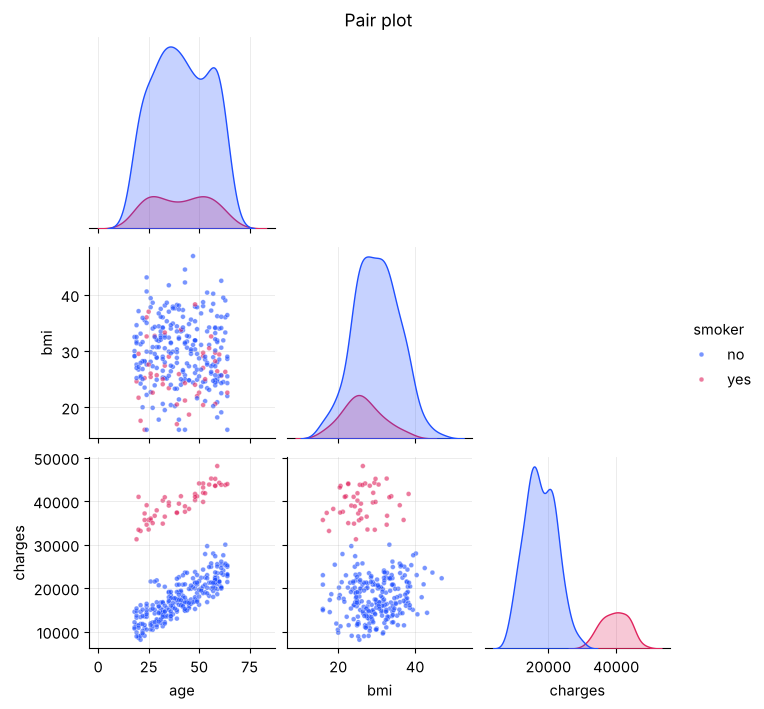

In [8]:
g = sns.pairplot(ins.sample(300, random_state=0), vars=["age", "bmi", "charges"],
                 hue="smoker", corner=True, plot_kws={"s": 12, "alpha": 0.6}, height=2.3)
g.figure.suptitle("Pair plot", y=1.02)
plt.show()

**Trend lines with uncertainty**

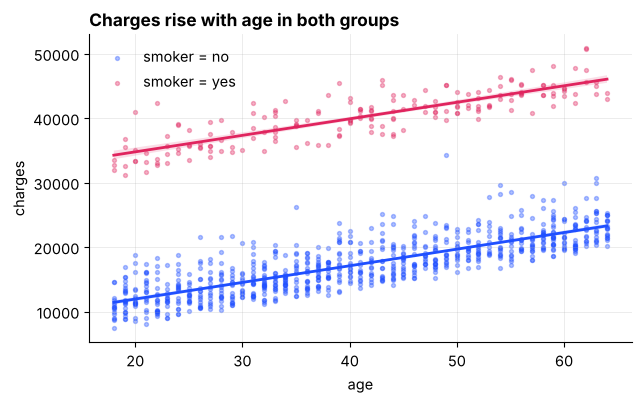

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for status, color in [("no", "#1f4fff"), ("yes", "#e0245e")]:
    sub = ins[ins["smoker"] == status]
    sns.regplot(data=sub, x="age", y="charges", scatter_kws={"s": 8, "alpha": 0.35},
                line_kws={"lw": 2}, color=color, label=f"smoker = {status}", ax=ax)
ax.legend()
ax.set_title("Charges rise with age in both groups")
plt.show()

## 14.5 Plotting directly from pandas · *Beginner*

**DataFrame.plot for quick looks**

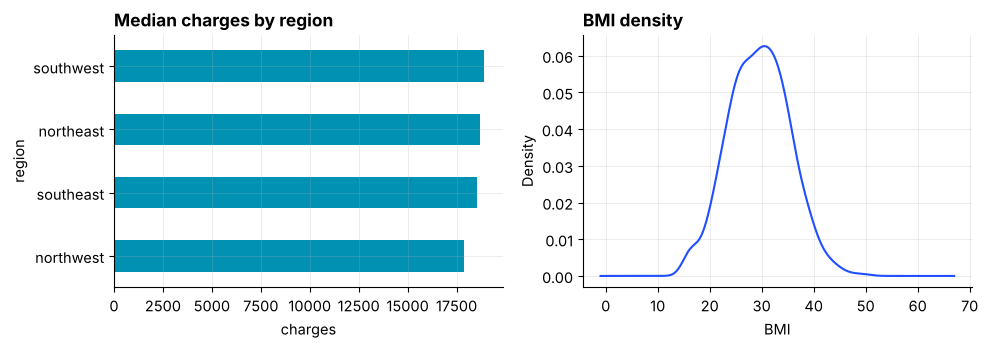

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ins.groupby("region")["charges"].median().sort_values().plot.barh(ax=axes[0], color="#0091b3")
axes[0].set(title="Median charges by region", xlabel="charges")
ins["bmi"].plot.kde(ax=axes[1])
axes[1].set(title="BMI density", xlabel="BMI")
plt.tight_layout()
plt.show()

## 14.6 Styles, colours and publication-quality export · *Intermediate*

**A reusable publication style**

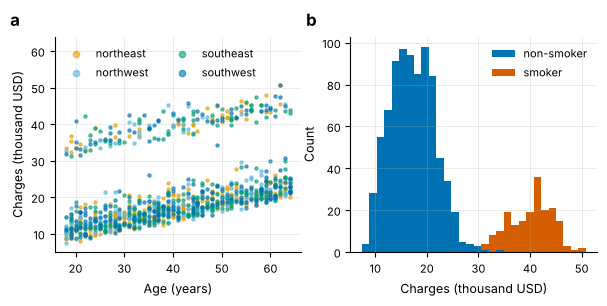

In [11]:
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "savefig.dpi": 300, "savefig.bbox": "tight",
})
okabe_ito = ["#E69F00", "#56B4E9", "#009E73", "#0072B2", "#D55E00", "#CC79A7"]
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.8))
for i, (name, grp) in enumerate(ins.groupby("region")):
    axes[0].scatter(grp["age"], grp["charges"] / 1000, s=5, alpha=0.6, color=okabe_ito[i], label=name)
axes[0].set(xlabel="Age (years)", ylabel="Charges (thousand USD)")
axes[0].set_ylim(5, 64)
axes[0].legend(markerscale=2, frameon=False, ncol=2, loc="upper left")
axes[1].hist([ins.loc[ins.smoker == s, "charges"] / 1000 for s in ("no", "yes")],
             bins=30, stacked=True, color=okabe_ito[3:5], label=["non-smoker", "smoker"])
axes[1].set(xlabel="Charges (thousand USD)", ylabel="Count")
axes[1].legend(frameon=False)
for ax, letter in zip(axes, "ab"):
    ax.text(-0.18, 1.05, letter, transform=ax.transAxes, fontsize=12, fontweight="bold")
fig.savefig("figure1.pdf")
fig.savefig("figure1.png", dpi=300)
fig.savefig("figure1.svg")
plt.show()
plt.rcdefaults()

## Try it yourself

1. Plot the histogram of `charges` and of `np.log(charges)` side by side. Which looks closer to normal?
2. Recreate the pair plot with `hue="region"`. Does region matter?
3. Make a bar chart of mean charges by number of children with error bars (`sns.barplot` shows a 95% CI by default).

Worked solutions: [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 14*.